# Tutorial Task: Wholesale Customer Segmentation with K-Means

## Background

A wholesale distributor wants to understand its customers' purchasing behaviour. The dataset records each customer's annual spending across six product categories. The goal is to identify groups of customers with similar purchasing patterns using **unsupervised cluster analysis**.

**Dataset:** 

The dataset contains 440 customers and 6 covariates:

- `Fresh`: annual spending on fresh products
- `Milk`: annual spending on milk products
- `Grocery`: annual spending on grocery products
- `Frozen`: annual spending on frozen products
- `Detergents_Paper`: annual spending on detergents and paper products
- `Delicassen`: annual spending on delicatessen products

## Learning objectives

By completing this exercise, you will practise importing and exploring real-world data, preparing numerical data for K-Means, selecting a plausible number of clusters, and interpreting clusters using PCA and conditional boxplots.

## Task 1 — Import and explore the data

1.1. Import the dataset from our Github repository.<br>
1.2. Plot a histogram for each spending variable . Use clear titles and axis labels.<br>
1.3. Briefly describe the distributions: Are they symmetric or skewed? Do you notice extreme values?<br>

## Task 2 — Preprocess the data and select K

2.1. Prepare the spending variables for K-Means. Explain why your chosen preprocessing is suitable for these data.<br>
2.2. Fit K-Means for a range of candidate values of `k` (for example, 2 to 10).<br>
2.3. Plot the within-cluster sum of squares (inertia) and the silhouette scores (from sklearn.metrics) against `k` in two separate lineplots, and choose a suitable value of `k`.<br>

## Task 3 — Visualize and interpret the clustering

Use your chosen value of `k` to fit a final K-Means model.

### 3.1 PCA scatterplot

3.1.1. Import `PCA` from `sklearn.decomposition`.<br>
3.1.2. Create a two-dimensional representation of the preprocessed input features.<br>
3.1.3. Plot the two principal components in a scatterplot, colour each point by its cluster assignment and interpret the plot. <br>

### 3.2 Conditional boxplots by cluster

Create **one boxplot figure per cluster**. Within each figure, show the distributions of all six spending variables for customers assigned to that cluster. You can log-transform the distributions if you establish extreme values. Interpret the figures.<br>
Conclude with a short summary of the customer segments you found and one limitation of your analysis.


## **Solutions**

### Task 1 — Import and explore the data



In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
X=pd.read_csv('Wholesale customers data.csv')

In [3]:
X.head()


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


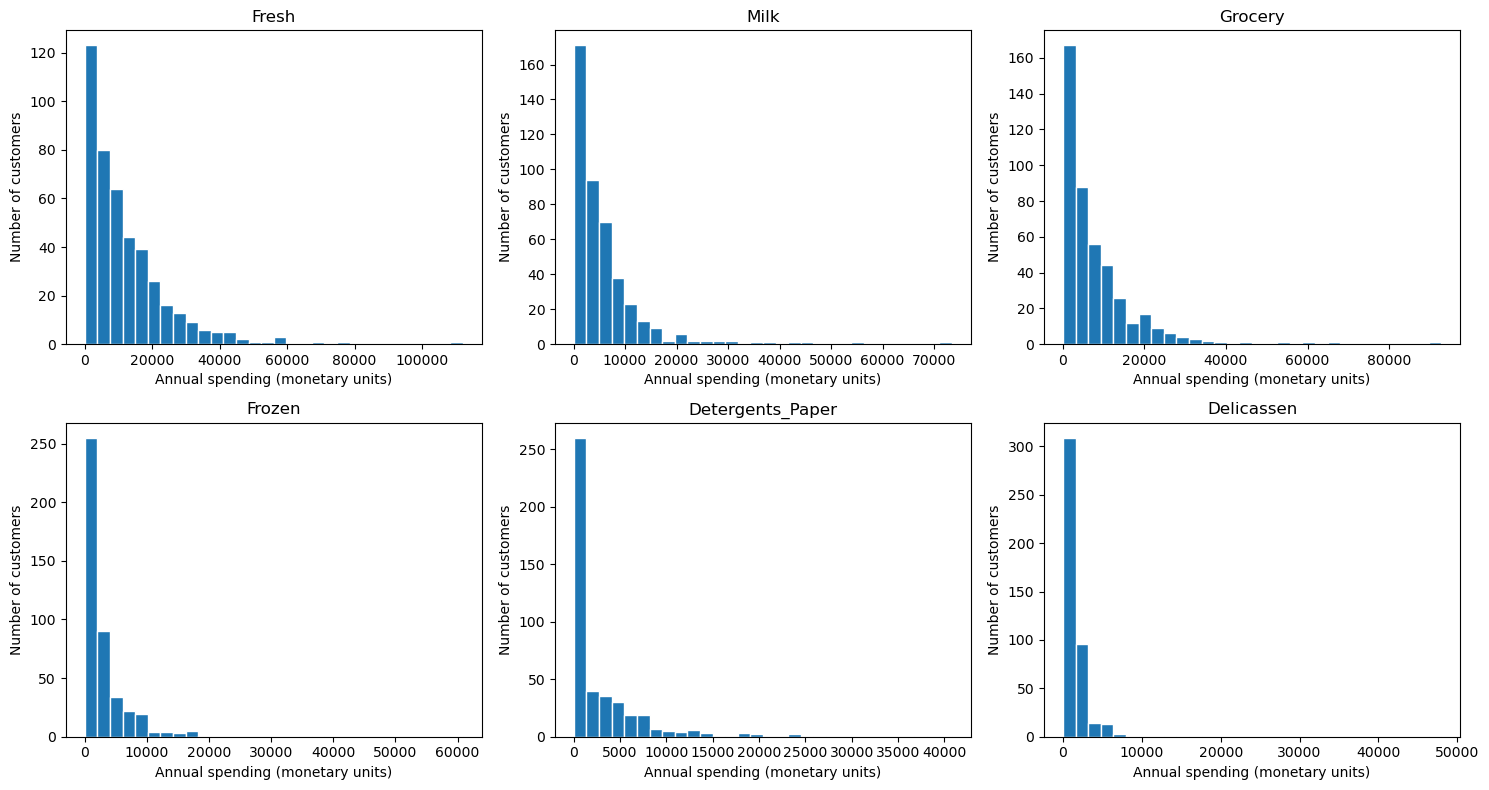

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, X.columns):
    ax.hist(X[column], bins=30, edgecolor="white")
    ax.set_title(column)
    ax.set_xlabel("Annual spending (monetary units)")
    ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

The distributions are generally right-skewed: many customers spend relatively modest amounts, while a smaller number spend much more. These extreme values and the differences in scale matter for distance-based methods such as K-Means.

### Task 2 — Preprocess the data and select K

K-Means uses distances, so variables with larger numeric scales can dominate the solution. The spending variables are also strongly right-skewed. Here, we will standardize each transformed feature to mean 0 and standard deviation 1. Addiitonally, one could also apply a logarithmic transformation prior to the standardization to reduce the skewness.

In [10]:
from sklearn.preprocessing import StandardScaler
X_log=np.log(X)
scaler = StandardScaler()
X_prepared = scaler.fit_transform(X_log)

print("Prepared feature matrix shape:", X_prepared.shape)

Prepared feature matrix shape: (440, 6)


The elbow plot shows how inertia decreases as more clusters are added. The silhouette score measures how well-separated observations are from neighbouring clusters; larger values are generally preferable. Use both plots to make a reasoned choice rather than treating either metric as a definitive answer.

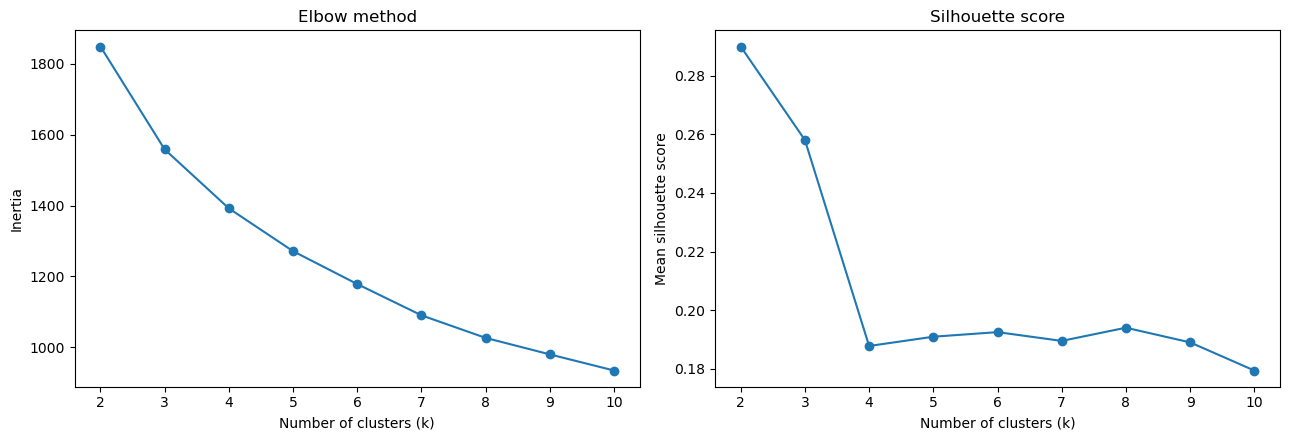

K with highest silhouette score in this range: 2
Silhouette scores: {2: 0.29, 3: 0.258, 4: 0.188, 5: 0.191, 6: 0.192, 7: 0.189, 8: 0.194, 9: 0.189, 10: 0.179}


In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_prepared)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_prepared, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Mean silhouette score")
axes[1].set_xticks(list(k_values))

plt.tight_layout()
plt.show()

best_silhouette_k = list(k_values)[int(np.argmax(silhouette_scores))]
print("K with highest silhouette score in this range:", best_silhouette_k)
print("Silhouette scores:", dict(zip(k_values, np.round(silhouette_scores, 3))))

In [20]:
optimal_k = best_silhouette_k

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=20)
cluster_labels = kmeans.fit_predict(X_prepared)

clustered = X.copy()
clustered["Cluster"] = cluster_labels

print("Selected k:", optimal_k)
print("Customers per cluster:")
display(clustered["Cluster"].value_counts().sort_index().rename("Number of customers").to_frame())

Selected k: 2
Customers per cluster:


,Number of customers
Cluster,
0,252
1,188


### Task 3 — Visualize and interpret the clustering

##### 3.1 PCA: project the input features into two dimensions

PCA finds directions that capture variation in the prepared feature matrix. It is used here to create a two-dimensional visualization; **PCA does not perform the clustering itself**.

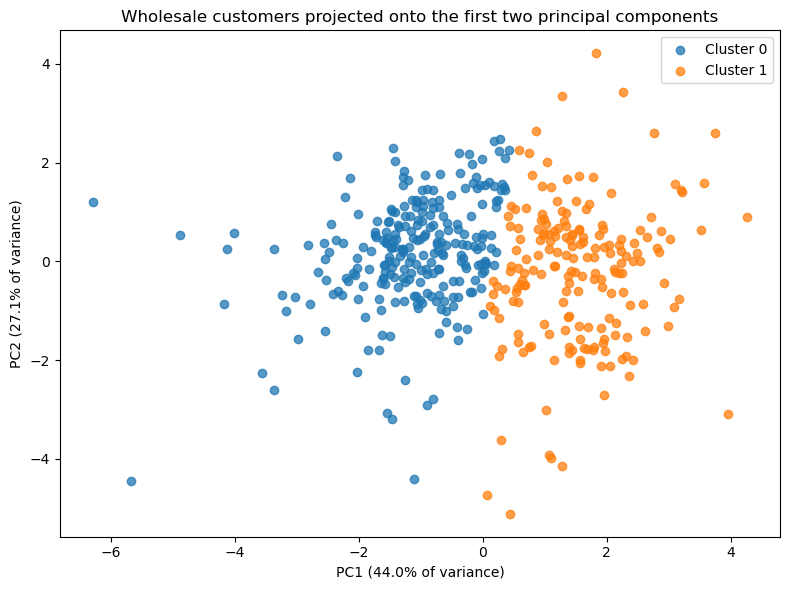

In [22]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_prepared)

pca_plot = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": cluster_labels.astype(str)
})

plt.figure(figsize=(8, 6))
for cluster in sorted(pca_plot["Cluster"].unique(), key=int):
    subset = pca_plot[pca_plot["Cluster"] == cluster]
    plt.scatter(subset["PC1"], subset["PC2"], label=f"Cluster {cluster}", alpha=0.75)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
plt.title("Wholesale customers projected onto the first two principal components")
plt.legend()
plt.tight_layout()
plt.show()



##### 3.2 Conditional boxplots: one figure per cluster

The boxplots below show the six spending variables for customers within each cluster. We use `log1p`-transformed spending so that the highly skewed distributions and extreme values are easier to inspect. The same transformed scale is used for every cluster figure.

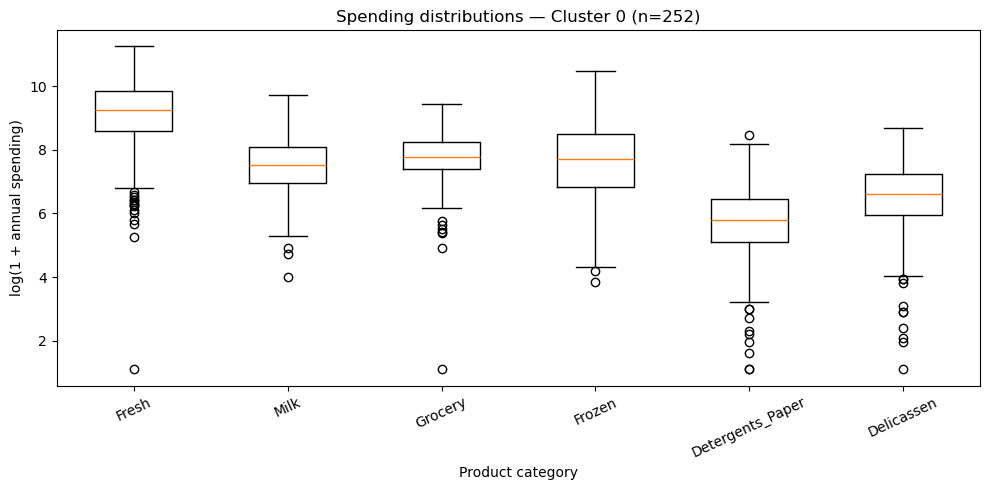

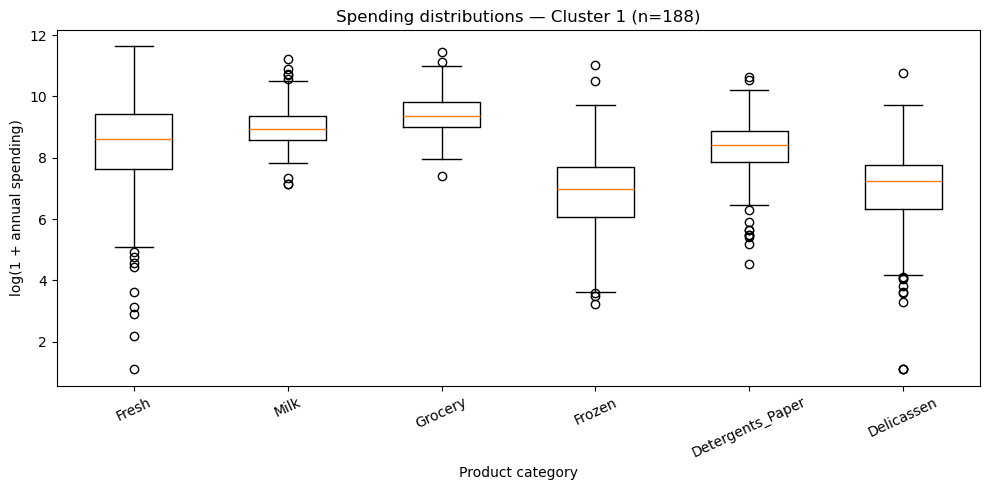

In [28]:
X_for_boxplots = np.log(X)

for cluster in sorted(np.unique(cluster_labels)):
    rows = cluster_labels == cluster
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.boxplot(
        [X_for_boxplots.loc[rows, col] for col in X_for_boxplots.columns],
        labels=X_for_boxplots.columns,
        showfliers=True
    )
    ax.set_title(f"Spending distributions — Cluster {cluster} (n={rows.sum()})")
    ax.set_ylabel("log(1 + annual spending)")
    ax.set_xlabel("Product category")
    ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()

### Bonus: Alternative way of examining quality of cluster solution:

Inspect the median spending by category for each cluster expressed in the original monetary units.

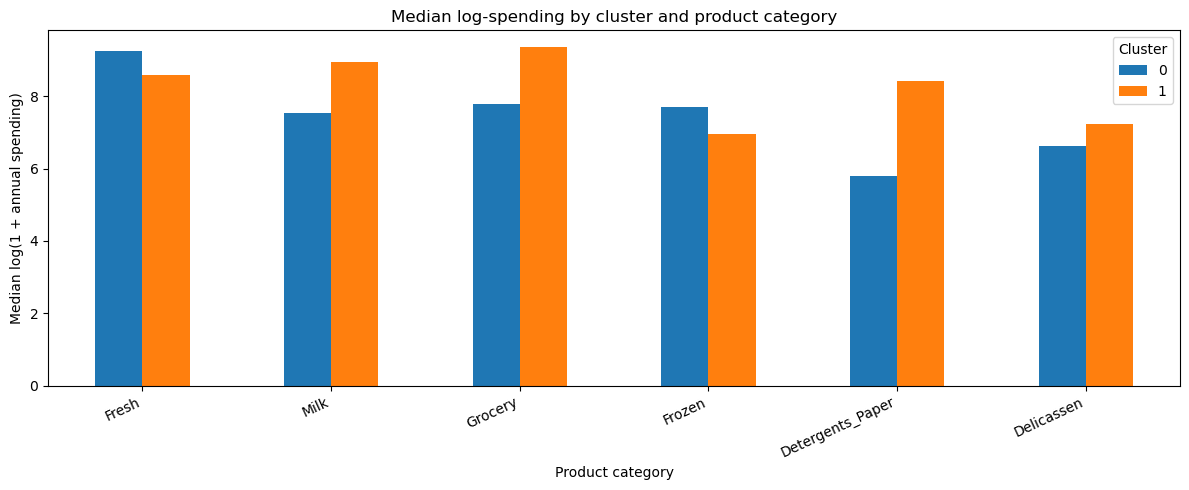

In [30]:
cluster_medians = clustered.groupby("Cluster")[X.columns].median().round(0)
#display(cluster_medians)

# Optional: compare profiles on a common relative scale using median log-spending.
profile = X_log.assign(Cluster=cluster_labels).groupby("Cluster").median()
ax = profile.T.plot(kind="bar", figsize=(12, 5))
ax.set_title("Median log-spending by cluster and product category")
ax.set_ylabel("Median log(1 + annual spending)")
ax.set_xlabel("Product category")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()